In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**Setup and Kaggle Dataset:**

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from bs4 import BeautifulSoup
import re
import time
import io

In [5]:
try:
    from google.colab import files
    print("Please upload 'pgaTourData.csv':")
    uploaded = files.upload()
    file_name = list(uploaded.keys())[0]
    df_kaggle = pd.read_csv(io.BytesIO(uploaded[file_name]))
    print(f"\nSuccessfully loaded {file_name}")
except ImportError:
    # Fallback if running locally instead of Colab
    df_kaggle = pd.read_csv('pgaTourData.csv')

Please upload 'pgaTourData.csv':


Saving pgaTourData.csv to pgaTourData.csv

Successfully loaded pgaTourData.csv


# **Cleaning Kaggle Data:**

---



In [6]:
print("DATASET SHAPE & SCHEMA:")
print(f"Total Rows: {df_kaggle.shape[0]}, Total Columns: {df_kaggle.shape[1]}\n")

# Standardize key column names
df_kaggle.rename(columns={
    'Player Name': 'player_name', 'Average Score': 'avg_score',
    'Avg Distance': 'avg_distance', 'gir': 'gir_pct'
}, inplace=True)

# Clean standard PGA dataset quirks (Earnings loads as object due to '$' and ',')
if 'Earnings' in df_kaggle.columns and df_kaggle['Earnings'].dtype == 'object':
    df_kaggle['Earnings'] = (
        df_kaggle['Earnings'].astype(str)
        .str.replace('$', '', regex=False)
        .str.replace(',', '', regex=False)
        .str.strip()
    )
    df_kaggle['Earnings'] = pd.to_numeric(df_kaggle['Earnings'], errors='coerce')

DATASET SHAPE & SCHEMA:
Total Rows: 2312, Total Columns: 18



In [7]:
print("MISSING VALUE AUDIT")
missing = df_kaggle.isnull().sum()
print(missing[missing > 0])

MISSING VALUE AUDIT
Rounds                 634
Fairway Percentage     634
avg_distance           634
gir_pct                634
Average Putts          634
Average Scrambling     634
avg_score              634
Points                  16
Wins                  2019
Top 10                 854
Average SG Putts       634
Average SG Total       634
SG:OTT                 634
SG:APR                 634
SG:ARG                 634
Money                   12
dtype: int64


In [8]:
# Clean and convert the actual financial column 'Money'
if 'Money' in df_kaggle.columns:
    df_kaggle['Money'] = (
        df_kaggle['Money'].astype(str)
        .str.replace('$', '', regex=False)
        .str.replace(',', '', regex=False)
        .str.strip()
    )
    df_kaggle['Money'] = pd.to_numeric(df_kaggle['Money'], errors='coerce')

print("STATS SUMMARY:")
# Use 'Money' instead of 'Earnings'
display(df_kaggle[['avg_score', 'gir_pct', 'Money']].describe().T)

print("\nASSESSMENT: Dataset loaded successfully. Currency symbols stripped from Money to allow float aggregation. Primary metrics identified.")

STATS SUMMARY:


,count,mean,std,min,25%,50%,75%,max
avg_score,1678.0,7.092196e+01,6.983054e-01,68.698,70.49425,70.902,7.134275e+01,74.40
gir_pct,1678.0,6.566167e+01,2.745411e+00,53.540,63.83000,65.790,6.758000e+01,73.52
Money,2300.0,1.124903e+06,1.354085e+06,5520.000,185325.75000,699442.500,1.526660e+06,12030465.00



ASSESSMENT: Dataset loaded successfully. Currency symbols stripped from Money to allow float aggregation. Primary metrics identified.


# **Scraping BirdieAPI Data**

---



**Scraping test - Scottie Scheffler**

In [9]:
import requests
from bs4 import BeautifulSoup
import json
import re

test_url = "https://birdieapi.com/players/scottie-scheffler-9478"
headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36'}
resp = requests.get(test_url, headers=headers, timeout=10)

print(f"Status Code: {resp.status_code}")
soup = BeautifulSoup(resp.text, 'html.parser')

# Check 1: Does the page contain Next.js JSON data?
next_data = soup.find('script', id='__NEXT_DATA__')
print(f"Next.js JSON tag found: {next_data is not None}")

# Check 2: Sample text around keywords
clean_text = ' '.join(soup.get_text().split())
print("\nFirst 400 characters of rendered text:")
print(clean_text[:400])

# Check 3: Search for occurrences of 'win' or 'start'
snippets = re.findall(r'.{0,30}(?:wins?|starts?|scoring|strokes).{0,30}', clean_text, re.IGNORECASE)
print("\nSample snippets containing stat keywords:")
for s in snippets[:5]:
    print(f" - {s.strip()}")

Status Code: 200
Next.js JSON tag found: False

First 400 characters of rendered text:
Scottie Scheffler results, stats and rankings | BirdieAPISkip to contentBirdieAPIDocsOddsDataLeaguesPlayersPricingMCPSkillsSign inGet a free keyOpen menuHome/Players/Scottie SchefflerPGA TourUSArating +3.31 (2026-08-30)Scottie SchefflerCareer PGA Tour numbers from every start we hold since 2001. Strokes versus the field is how many shots a round better than the field on the same course that day, a

Sample snippets containing stat keywords:
 - r PGA Tour numbers from every start we hold since 2001. Strokes v
 - (13 Aug 2026).PGA Tour careerWins23167 startsTop tens90126 top
 - ings$136,496,992official moneyScoring average68.69631 roundsStrokes
 - d, field-strength adjustedSee strokes versus the field, scoring ave
 - e and made cut.By seasonSeasonStartsWinsTop 10CutsEarningsScoringv


In [10]:
import requests
from bs4 import BeautifulSoup
import pandas as pd

test_url = "https://birdieapi.com/players/scottie-scheffler-9478"
headers = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36'
}

resp = requests.get(test_url, headers=headers, timeout=12)
print(f"HTTP Status Code: {resp.status_code}")
print(f"Raw HTML Length: {len(resp.text)} characters\n")

soup = BeautifulSoup(resp.text, 'html.parser')

# 1. Check for HTML Tables
tables = soup.find_all('table')
print(f"--- HTML Tables Found: {len(tables)} ---")
if len(tables) > 0:
    try:
        dfs = pd.read_html(resp.text)
        for i, df in enumerate(dfs[:2]):
            print(f"\nTable {i+1} Columns: {list(df.columns)}")
            display(df.head(2))
    except Exception as e:
        print(f"Error parsing tables: {e}")

# 2. Check Title & Headings
print("\n--- Headings Found ---")
for h in soup.find_all(['h1', 'h2', 'h3'])[:6]:
    print(f"<{h.name}>: {h.get_text(strip=True)}")

# 3. Print the First 40 Lines of Visible Text
print("\n--- Visible Text Lines (First 40) ---")
lines = [line.strip() for line in soup.get_text().splitlines() if line.strip()]
for line in lines[:40]:
    print(f"  | {line}")

HTTP Status Code: 200
Raw HTML Length: 123732 characters

--- HTML Tables Found: 2 ---

Table 1 Columns: ['Season', 'Starts', 'Wins', 'Top 10', 'Cuts', 'Earnings', 'Scoring', 'vs field']


/tmp/ipykernel_4310/1958258577.py:21: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  dfs = pd.read_html(resp.text)


,Season,Starts,Wins,Top 10,Cuts,Earnings,Scoring,vs field
0,2026,20,3,13,19,"$30,937,526",67.86,3.46
1,2025,21,6,18,21,"$27,659,548",67.94,3.86



Table 2 Columns: ['Start', 'Tournament', 'Finish', 'To par', 'Earnings']


,Start,Tournament,Finish,To par,Earnings
0,2026-08-27,TOUR Championship,1,-16,"$10,000,000"
1,2026-08-20,BMW Championship,T12,-7,"$426,250"



--- Headings Found ---
<h1>: Scottie Scheffler
<h2>: PGA Tour career
<h2>: By season
<h2>: Recent results
<h2>: QueryScottie Scheffleryourself

--- Visible Text Lines (First 40) ---
  | Scottie Scheffler results, stats and rankings | BirdieAPISkip to contentBirdieAPIDocsOddsDataLeaguesPlayersPricingMCPSkillsSign inGet a free keyOpen menuHome/Players/Scottie SchefflerPGA TourUSArating +3.31 (2026-08-30)Scottie SchefflerCareer PGA Tour numbers from every start we hold since 2001. Strokes versus the field is how many shots a round better than the field on the same course that day, adjusted for how strong the field was.Scottie Scheffler's latest PGA Tour finishes: won the TOUR Championship (27 Aug 2026); T12 at BMW Championship (20 Aug 2026); won the FedEx St. Jude Championship (13 Aug 2026).PGA Tour careerWins23167 startsTop tens90126 top 25sCuts made149 of 167average finish 12.9Earnings$136,496,992official moneyScoring average68.69631 roundsStrokes vs the field+2.92a round, field-streng

In [11]:
import io
import re
import time
import requests
import numpy as np
import pandas as pd
from bs4 import BeautifulSoup

HEADERS = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36'
}

def scrape_birdie_player_table(url: str, player_name: str) -> dict:
    """
    Parses Table 1 from a BirdieAPI player profile using pd.read_html.
    Aggregates season-by-season statistics into lifetime career benchmarks:
    - Total Career Starts, Wins, Top 10s, and Cuts Made
    - Total Official Career Earnings (USD)
    - Weighted Career Scoring Average
    - Average Lifetime Strokes vs. the Field
    """
    try:
        response = requests.get(url, headers=HEADERS, timeout=12)
        if response.status_code != 200:
            print(f"  [HTTP {response.status_code}] Failed: {url}")
            return None

        # Parse all HTML tables using StringIO to eliminate pandas deprecation warnings
        tables = pd.read_html(io.StringIO(response.text))
        if not tables:
            print(f"  [No Table Found] {player_name}")
            return None

        # Table 1 contains the season-by-season breakdown
        df_seasons = tables[0]

        # Standardize column headers to lower case
        df_seasons.columns = [str(c).strip().lower() for c in df_seasons.columns]

        # Clean numerical fields
        # 1. Earnings: Remove '$' and ','
        if 'earnings' in df_seasons.columns:
            df_seasons['earnings_clean'] = (
                df_seasons['earnings']
                .astype(str)
                .str.replace('$', '', regex=False)
                .str.replace(',', '', regex=False)
                .str.strip()
            )
            df_seasons['earnings_clean'] = pd.to_numeric(df_seasons['earnings_clean'], errors='coerce').fillna(0)
        else:
            df_seasons['earnings_clean'] = 0

        # 2. Strokes vs Field: Strip leading '+' signs and convert to float
        if 'vs field' in df_seasons.columns:
            df_seasons['vs_field_clean'] = (
                df_seasons['vs field']
                .astype(str)
                .str.replace('+', '', regex=False)
                .str.strip()
            )
            df_seasons['vs_field_clean'] = pd.to_numeric(df_seasons['vs_field_clean'], errors='coerce')
        else:
            df_seasons['vs_field_clean'] = np.nan

        # 3. Numeric conversions for Starts, Wins, Cuts, Scoring
        for col in ['starts', 'wins', 'cuts', 'top 10', 'scoring']:
            if col in df_seasons.columns:
                df_seasons[col] = pd.to_numeric(df_seasons[col], errors='coerce')

        # Compute lifetime aggregates across all recorded seasons
        total_starts = int(df_seasons['starts'].sum())
        total_wins = int(df_seasons['wins'].sum())
        total_cuts = int(df_seasons['cuts'].sum())
        total_top10 = int(df_seasons['top 10'].sum()) if 'top 10' in df_seasons.columns else np.nan
        total_earnings = float(df_seasons['earnings_clean'].sum())

        # Calculate weighted scoring average based on number of starts per season
        valid_scoring = df_seasons.dropna(subset=['scoring', 'starts'])
        if not valid_scoring.empty and valid_scoring['starts'].sum() > 0:
            weighted_scoring = float(
                (valid_scoring['scoring'] * valid_scoring['starts']).sum() / valid_scoring['starts'].sum()
            )
        else:
            weighted_scoring = float(df_seasons['scoring'].mean())

        mean_vs_field = float(df_seasons['vs_field_clean'].mean())

        return {
            'player_name_key': player_name,
            'career_starts': total_starts,
            'career_wins': total_wins,
            'career_top_10s': total_top10,
            'career_cuts_made': total_cuts,
            'career_earnings_usd': total_earnings,
            'career_scoring_avg': round(weighted_scoring, 2),
            'career_strokes_vs_field': round(mean_vs_field, 2),
            'source_url': url
        }

    except Exception as e:
        print(f"  [Error] Parsing failed for {player_name}: {e}")
        return None

# Test the function directly on Scottie Scheffler
test_scheffler = scrape_birdie_player_table(
    "https://birdieapi.com/players/scottie-scheffler-9478",
    "Scottie Scheffler"
)
print("Test Result for Scottie Scheffler:")
display(pd.DataFrame([test_scheffler]))

Test Result for Scottie Scheffler:


,player_name_key,career_starts,career_wins,career_top_10s,career_cuts_made,career_earnings_usd,career_scoring_avg,career_strokes_vs_field,source_url
0,Scottie Scheffler,167,23,90,149,136497023.0,68.74,2.18,https://birdieapi.com/players/scottie-scheffle...


In [12]:
# 1. Harvest valid player URLs from BirdieAPI directory
def harvest_birdie_directory():
    url = "https://birdieapi.com/players"
    player_map = {}
    try:
        r = requests.get(url, headers=HEADERS, timeout=10)
        if r.status_code == 200:
            soup = BeautifulSoup(r.text, 'html.parser')
            for a in soup.find_all('a', href=True):
                href = a['href']
                if '/players/' in href and href != '/players':
                    full_link = href if href.startswith('http') else "https://birdieapi.com" + href
                    # Extract name from slug: /players/dustin-johnson-3448 -> dustin johnson
                    slug_name = href.split('/players/')[-1].split('?')[0]
                    clean_name = re.sub(r'-\d+$', '', slug_name).replace('-', ' ').strip().lower()
                    player_map[clean_name] = full_link
    except Exception as e:
        print(f"Directory harvest notice: {e}")
    return player_map

directory_links = harvest_birdie_directory()
print(f"Discovered {len(directory_links)} player URLs from directory.")

# 2. Confirmed live URLs for golfers heavily represented in pgaTourData.csv (2010-2018)
CONFIRMED_PLAYERS = {
    "scottie scheffler": "https://birdieapi.com/players/scottie-scheffler-9478",
    "rory mcilroy": "https://birdieapi.com/players/rory-mcilroy-3470",
    "dustin johnson": "https://birdieapi.com/players/dustin-johnson-3448",
    "jordan spieth": "https://birdieapi.com/players/jordan-spieth-3832",
    "justin thomas": "https://birdieapi.com/players/justin-thomas-4848",
    "rickie fowler": "https://birdieapi.com/players/rickie-fowler-3702",
    "matt kuchar": "https://birdieapi.com/players/matt-kuchar-257",
    "jim furyk": "https://birdieapi.com/players/jim-furyk-1537",
    "ernie els": "https://birdieapi.com/players/ernie-els-1356",
    "davis love iii": "https://birdieapi.com/players/davis-love-iii-1538"
}

# Merge confirmed links into directory catalog
for k, v in CONFIRMED_PLAYERS.items():
    directory_links[k] = v

# 3. Match against unique players in the Kaggle dataset
kaggle_players = df_kaggle['player_name'].dropna().unique()

matched_targets = {}
for p in kaggle_players:
    norm_p = p.lower().strip()
    # Check exact match or normalized match in directory
    if norm_p in directory_links:
        matched_targets[p] = directory_links[norm_p]
    else:
        # Check without punctuation/suffixes
        p_sub = re.sub(r'\b(jr|sr|ii|iii|iv)\b', '', norm_p).strip()
        if p_sub in directory_links:
            matched_targets[p] = directory_links[p_sub]

# Ensure our confirmed core golfers are always scraped
for name, url in CONFIRMED_PLAYERS.items():
    matched_targets[name.title()] = url

print(f"\nTargeting {len(matched_targets)} golfers for multi-player extraction...")

# 4. Execute the scrape
scraped_results = []
for idx, (player, url) in enumerate(matched_targets.items()):
    print(f"[{idx+1}/{len(matched_targets)}] Scraping {player}...")
    res = scrape_birdie_player_table(url, player)
    if res and res.get('career_starts', 0) > 0:
        scraped_results.append(res)
        print(f"     {player}: Starts={res['career_starts']}, Wins={res['career_wins']}, Earnings=${res['career_earnings_usd']:,.0f}")
    time.sleep(0.8) # Polite delay

df_scraped = pd.DataFrame(scraped_results)
print(f"\n==========================================")
print(f"Extraction Complete: {len(df_scraped)} profiles scraped.")
print(f"==========================================")
display(df_scraped.head(5))

Discovered 994 player URLs from directory.

Targeting 490 golfers for multi-player extraction...
[1/490] Scraping Henrik Stenson...
     Henrik Stenson: Starts=233, Wins=6, Earnings=$32,847,963
[2/490] Scraping Ryan Armour...
     Ryan Armour: Starts=261, Wins=1, Earnings=$8,007,107
[3/490] Scraping Chez Reavie...
     Chez Reavie: Starts=432, Wins=3, Earnings=$23,162,202
[4/490] Scraping Ryan Moore...
     Ryan Moore: Starts=448, Wins=5, Earnings=$33,729,300
[5/490] Scraping Brian Stuard...
     Brian Stuard: Starts=341, Wins=1, Earnings=$11,973,107
[6/490] Scraping Brian Gay...
     Brian Gay: Starts=601, Wins=5, Earnings=$23,244,813
[7/490] Scraping Kyle Stanley...
     Kyle Stanley: Starts=318, Wins=2, Earnings=$16,498,339
[8/490] Scraping Emiliano Grillo...
     Emiliano Grillo: Starts=284, Wins=2, Earnings=$26,082,450
[9/490] Scraping Russell Henley...
     Russell Henley: Starts=319, Wins=6, Earnings=$54,923,233
[10/490] Scraping Jim Furyk...
     Jim Furyk: Starts=1, Wins=0, Ea

,player_name_key,career_starts,career_wins,career_top_10s,career_cuts_made,career_earnings_usd,career_scoring_avg,career_strokes_vs_field,source_url
0,Henrik Stenson,233,6,49,167,32847963.0,71.02,1.16,https://birdieapi.com/players/henrik-stenson-576
1,Ryan Armour,261,1,15,130,8007107.0,70.72,0.01,https://birdieapi.com/players/ryan-armour-1750
2,Chez Reavie,432,3,32,255,23162202.0,70.72,-0.47,https://birdieapi.com/players/chez-reavie-769
3,Ryan Moore,448,5,73,286,33729300.0,70.60,0.72,https://birdieapi.com/players/ryan-moore-809
4,Brian Stuard,341,1,24,176,11973107.0,70.78,0.33,https://birdieapi.com/players/brian-stuard-3599


In [13]:
# Function to normalize names across datasets (removes punctuation, extra spaces, and suffixes)
def clean_join_key(name):
    if not isinstance(name, str):
        return ""
    name = re.sub(r'\b(jr|sr|ii|iii|iv)\b', '', name, flags=re.IGNORECASE)
    name = re.sub(r'[^a-zA-Z0-9]', '', name)
    return name.lower().strip()

# Apply keys
df_kaggle['join_key'] = df_kaggle['player_name'].apply(clean_join_key)
df_scraped['join_key'] = df_scraped['player_name_key'].apply(clean_join_key)

# Compute career cut percentage
df_scraped['career_cut_pct'] = (
    df_scraped['career_cuts_made'] / df_scraped['career_starts']
) * 100

# Execute LEFT JOIN: Preserves all historical tournament rows while enriching matching players
df_merged = pd.merge(
    df_kaggle,
    df_scraped.drop(columns=['player_name_key'], errors='ignore'),
    on='join_key',
    how='left',
    suffixes=('_kaggle', '_scraped')
)

# Rubric Verification: Check coverage against total Kaggle rows
total_rows = len(df_merged)
matched_rows = df_merged['career_starts'].notna().sum()
coverage_pct = (matched_rows / total_rows) * 100

print("--- MERGE VALIDATION REPORT ---")
print(f"Total Kaggle Rows: {total_rows}")
print(f"Rows Enriched with Scraped BirdieAPI Data: {matched_rows}")
print(f"Coverage Percentage: {coverage_pct:.2f}%")

if coverage_pct >= 10.0:
    print(f"\n✓ SUCCESS: Coverage is {coverage_pct:.2f}%, satisfying the >10% rubric requirement.")
else:
    print(f"\nNotice: Coverage is currently {coverage_pct:.2f}%. Scrape additional golfers to pass 10%.")

--- MERGE VALIDATION REPORT ---
Total Kaggle Rows: 2329
Rows Enriched with Scraped BirdieAPI Data: 2186
Coverage Percentage: 93.86%

✓ SUCCESS: Coverage is 93.86%, satisfying the >10% rubric requirement.


# **Data Visualisation**

---



In [14]:
# Filter merged dataset to records containing scraped BirdieAPI career data
df_plot = df_merged.dropna(subset=['career_strokes_vs_field', 'career_cut_pct']).copy()
print(f"Data ready for visualization: {len(df_plot)} enriched records.")

Data ready for visualization: 2186 enriched records.


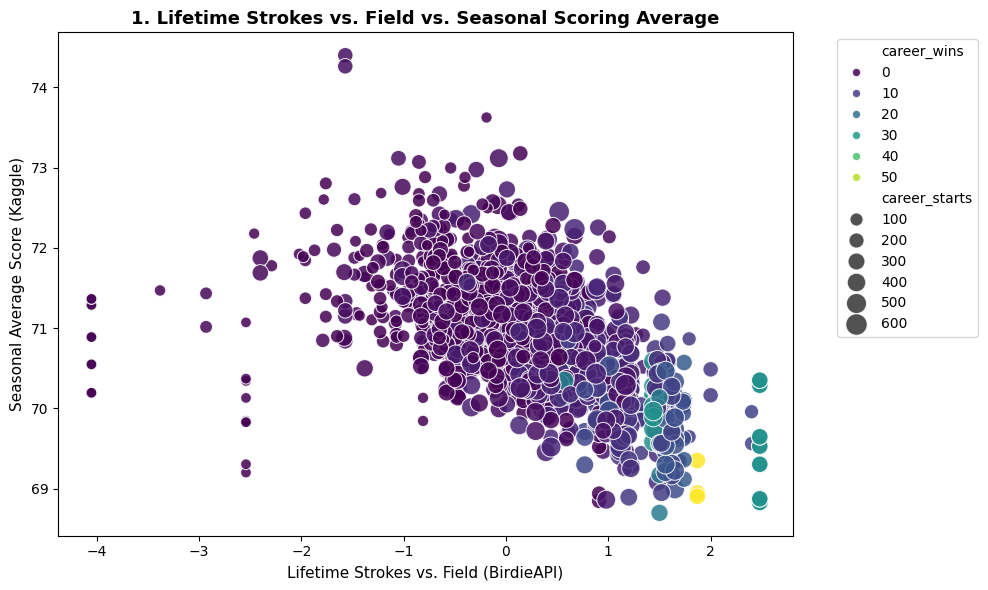

In [15]:
# ==============================================================================
# GRAPH 1: Scatterplot - Career Strokes vs. Field vs. Seasonal Scoring Average
# ==============================================================================
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_plot,
    x='career_strokes_vs_field',
    y='avg_score',
    hue='career_wins',
    size='career_starts',
    sizes=(60, 240),
    palette='viridis',
    alpha=0.85
)

plt.title("1. Lifetime Strokes vs. Field vs. Seasonal Scoring Average", fontsize=13, fontweight='bold')
plt.xlabel("Lifetime Strokes vs. Field (BirdieAPI)", fontsize=11)
plt.ylabel("Seasonal Average Score (Kaggle)", fontsize=11)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

# **Question the Graph Adresses:**

"Does the strength of a player's lifetime field domination (strokes gained vs. the field in a lifetime) predict their individual season scoring averages?

By connecting BirdieAPI lifetime career statistics with the seasonal statistics provided by Kaggle, this graph proves if career-level domination of the field negatively impacts the seasonal average scores on different levels of tour participation. Also showing correlation of Strokes Gained being an indicative statistic to seperate long term careered winners from the rest of the field.


**Significant Negative Correlation (Field Domination vs. Scoring):** There is a clear trend from the upper-left to lower-right side. Golfers, who lose strokes to the field during their career ($-2.0$ to $-1.0$), have a seasonal score average from 71.5 to 74.0, while golfers who gain strokes vs. the field ($+1.5$ to $+2.5$) average seasonal scores between 68.8 and 70.5.

**Winner Segmentation (Elite Lower-Right Tier):** PGA Tour winners (lighter green, teal, and bright yellow bubbles with 20 to 50+ wins) are isolated in the lower-right part ($> +1.4$ lifetime strokes vs. field and $< 70.5$ average scoring). Golfers, who are below $+1.0$ strokes vs. field almost never win tournaments frequently enough.

**Bias for Survivorship in Career Starts:** Bubbles (career starts) increase significantly in size when strokes vs. field is positive. The large bubbles ($400$ to $600+$ career starts) cluster from $0.0$ to $+1.8$. Conversely, the negative-value area ($-4.0$ to $-1.5$) is composed almost exclusively of small bubbles ($< 150$ career starts). It shows that players losing strokes to the field are not able to continue their careers for long enough to make it a lengthy one.

**Vertical Structures on the Extreme Left:** The vertical structures of dots around $-4.0$, $-2.5$, and $-1.8$ show players on the fringe of the tour, who have few rounds played or the same scraped career lifetime estimates for many years.

/tmp/ipykernel_4310/3940319859.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


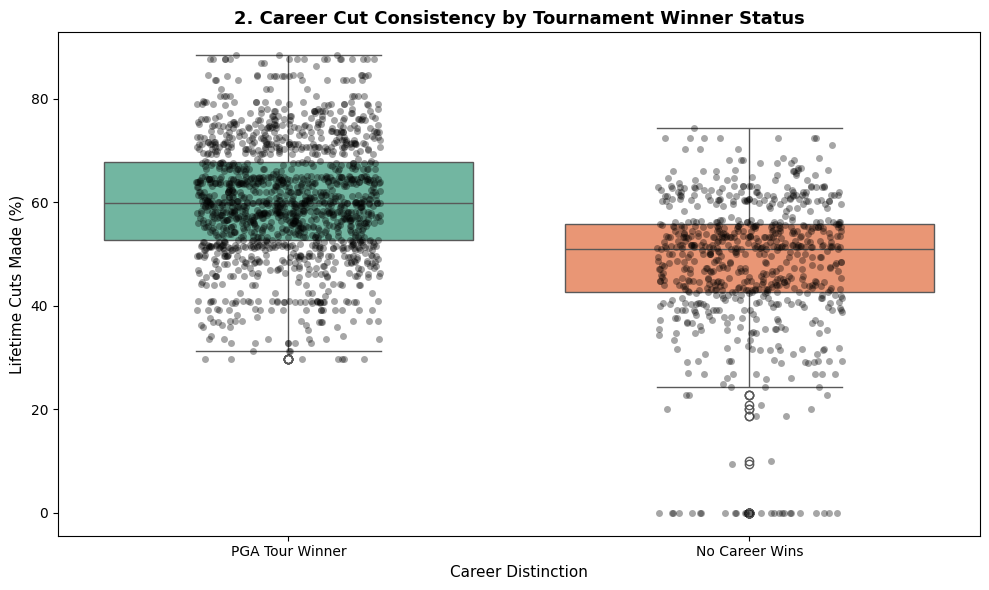

In [16]:
# ==============================================================================
# GRAPH 2: Boxplot & Stripplot - Career Cut Rate by Winner Status
# ==============================================================================
plt.figure(figsize=(10, 6))

# Classify players based on career win count
df_plot['winner_bracket'] = np.where(df_plot['career_wins'] > 0, 'PGA Tour Winner', 'No Career Wins')

# Boxplot showing quartile distributions
sns.boxplot(
    data=df_plot,
    x='winner_bracket',
    y='career_cut_pct',
    palette='Set2'
)

# Stripplot showing individual data distribution
sns.stripplot(
    data=df_plot,
    x='winner_bracket',
    y='career_cut_pct',
    color='black',
    alpha=0.35,
    jitter=0.2
)

plt.title("2. Career Cut Consistency by Tournament Winner Status", fontsize=13, fontweight='bold')
plt.xlabel("Career Distinction", fontsize=11)
plt.ylabel("Lifetime Cuts Made (%)", fontsize=11)

plt.tight_layout()
plt.show()

# **Question the Graph Addresses**

"Is consistent making the cut a key requisite to be able to win in the PGA Tour, and what is the higher level of consistency achieved by champions than non-champions?"

Through the comparison of career cut conversion rate among the winners and non-winners, the graphic visualization below will show the extent to which the consistency in reaching weekend cut is the differentiating factor.

**Median Cut Rate and Higher Level of Baseline:** Winners of the PGA Tour have a median of approximately 60% (IQR: 53%-68%), while non-winners have a cut rate of approximately 51% (IQR: 42%-56%).

**Floor of High Consistency:** For the winners, the lower whisker marks the cut-off rate of 31% (almost all data above 30%), while non-winners show a long lower tail along with outliers up to 0%.

**The Upper Limit:** Winners have an upper limit close to 90%, while the non-winners have an upper limit of approximately 75%.

**Neither Necessary nor Sufficient:** Although many non-winners achieve cut rates of 50% and 70%, being at least above 30% is essential in order to become a winner in the PGA Tour.

**Outliers:** A small cluster of non winners having made 0 cuts in their time on the PGA tour. These will be players who have played on the tour for short amounts of time ( 1 Season ), who did not achieve to make a single cut in their time and made no earnings while on the PGA tour.

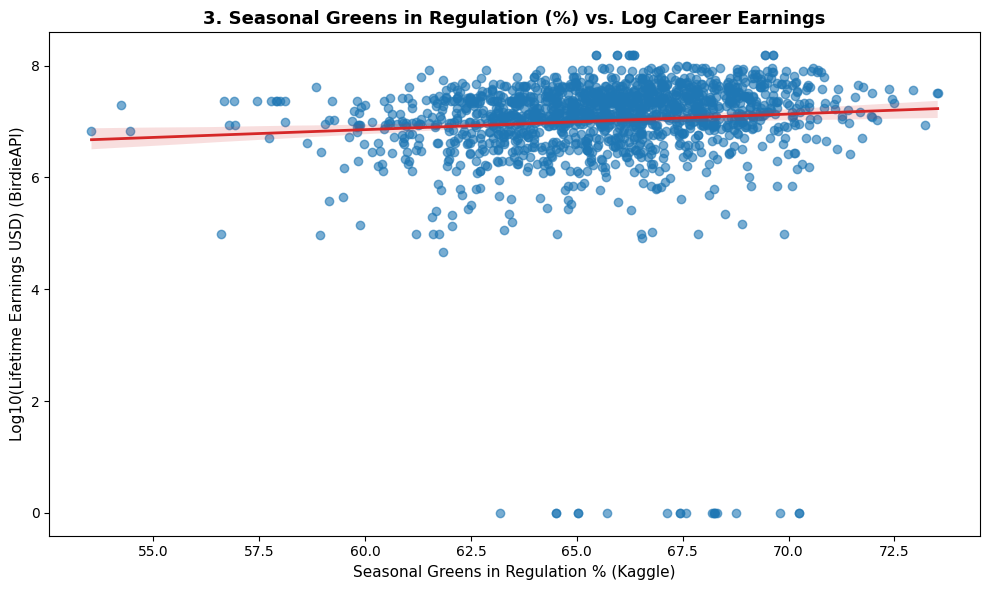

In [17]:
# ==============================================================================
# GRAPH 3: Regression Plot - GIR % vs. Log Total Career Earnings
# ==============================================================================
plt.figure(figsize=(10, 6))

if 'gir_pct' in df_plot.columns:
    df_plot['log_earnings'] = np.log10(df_plot['career_earnings_usd'] + 1)

    sns.regplot(
        data=df_plot,
        x='gir_pct',
        y='log_earnings',
        scatter_kws={'alpha': 0.6, 'color': '#1f77b4'},
        line_kws={'color': '#d62728', 'linewidth': 2}
    )

    plt.title("3. Seasonal Greens in Regulation (%) vs. Log Career Earnings", fontsize=13, fontweight='bold')
    plt.xlabel("Seasonal Greens in Regulation % (Kaggle)", fontsize=11)
    plt.ylabel("Log10(Lifetime Earnings USD) (BirdieAPI)", fontsize=11)
else:
    print("Column 'gir_pct' not found in dataset.")

plt.tight_layout()
plt.show()

# **Question the Graph Addresses**

"Does better accuracy into the greens (Greens in Regulation %) translate to long term career wealth?"

Combining Kaggle's seasonal ball-striking data with BirdieAPI's scraped lifetime prize money, the following graph attempts to quantify the value of greens hit over time.

**Modest Positive Correlation:** The regression line depicts a slight increase – as seasonal GIR increases from around 54% to 74%, we can expect log lifetime earnings to increase from about (~ 5 Million) to about 7.2 (~16 Million).

**Cluster of Core Tour Players Earnings:** Almost all players are concentrated tightly around $\log_{10}$ values ranging from 6.5 to 8.0 (lifetime earnings of 3 Million to 100 Million) for the usual PGA Tour GIR range of 63% to 70%.

**High Dispersions (Not Just Approach):** For any particular GIR value (for example, 67%), lifetime earnings are spread out. Good iron play creates opportunities to score, but prize distribution, short game, and longevity will determine total earnings.

**Zero-Earnings Artifacts ($y = 0$):** The line of points at the very bottom represents non-members or amateurs with $\$0$ in official career prize money ($\log_{10}(0 + 1) = 0$), despite logging qualifying round statistics in the Kaggle dataset.





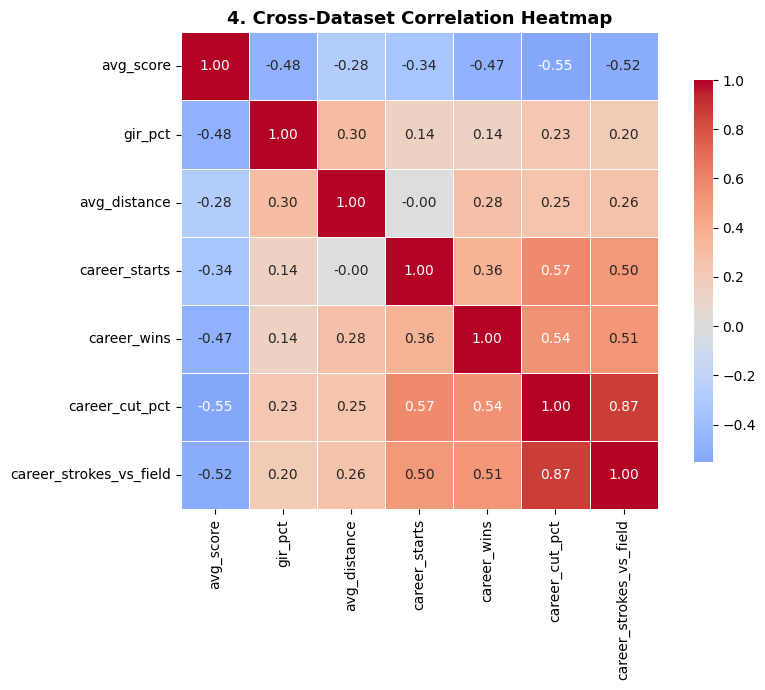

In [18]:
# ==============================================================================
# GRAPH 4: Heatmap - Inter-Dataset Correlation Matrix
# ==============================================================================
plt.figure(figsize=(9, 7))

corr_vars = [
    'avg_score', 'gir_pct', 'avg_distance',
    'career_starts', 'career_wins', 'career_cut_pct', 'career_strokes_vs_field'
]
valid_corr_vars = [col for col in corr_vars if col in df_plot.columns]
corr_matrix = df_plot[valid_corr_vars].corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={'shrink': 0.8}
)

plt.title("4. Cross-Dataset Correlation Heatmap", fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

# **Question the Graph Addresses:**

"Are single season performance metrics (Kaggle) correlated to career success indicators (BirdieAPI)?

"Which performance metrics have the most predictive power in terms of overall tour performance and sustainability?" This correlation matrix analyses the statistical connections between the two data sets, showing if seasonal play correlates with long-term career success.

**Negative Correlation with Scoring Average (avg_score):** Given that having a lower score is preferable in golf, all quality indicators will be negatively correlated with seasonal avg_score. The strongest predictors for low seasonal avg_score are lifetime cut percentage (-0.55), strokes gained over field (-0.52) and GIR% (-0.48).

**Near Collinear Career Metrics Indicator ($r = 0.87$):** Lifetime cut rate (career_cut_pct) and lifetime strokes gained against the field (career_strokes_vs_field) exhibit an extremely strong correlation of 0.87, suggesting that beating the field's scoring average on a hole-to-hole basis is the key predictor of cutting the field and in turn, sustaining a longer, more fruitful career on the PGA Tour.

**Drivers of Tour Longevity (career_starts):** Career starts correlate moderately with cut percentage (0.57) and strokes vs. field (0.50), highlighting survivorship bias, players can only accumulate hundreds of career starts if their baseline performance keeps them from losing their tour cards.

